##About Dataset

###Context

This is a very clean dataset and is for anyone who wants to try his/her hand on the NER ( Named Entity recognition ) task of NLP.

###Content

The dataset with 1M x 4 dimensions contains columns = ['# Sentence', 'Word', 'POS', 'Tag'] and is grouped by #Sentence.

###Columns

Word:
This column contains English dictionary words form the sentence it is taken from.

POS:
Parts of speech tag

Tag:
Standard named entity recognition tags as follows

ORGANIZATION - Georgia-Pacific Corp., WHO

PERSON - Eddy Bonte, President Obama

LOCATION - Murray River, Mount Everest

DATE - June, 2008-06-29

TIME - two fifty a m, 1:30 p.m.

MONEY - 175 million Canadian Dollars, GBP 10.40

PERCENT - twenty pct, 18.75 %

FACILITY - Washington Monument, Stonehenge

GPE - South East Asia, Midlothian



link to Kaggle : https://www.kaggle.com/datasets/debasisdotcom/name-entity-recognition-ner-dataset


PARTIE A

la premiére fonction fais du nettotage du texte : mettre en miniscule + supprisssion de la ponctuation + suprressions des espaces redondants

la deuxiéme fonction on utilise spacy pour recuperer les tokens + les pos_tags + les lemmes


In [32]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("/content/NER_dataset.csv", encoding="latin1")

In [6]:
data

,Sentence #,Word,POS,Tag
0,Sentence: 1,Thousands,NNS,O
1,NaN,of,IN,O
2,NaN,demonstrators,NNS,O
3,NaN,have,VBP,O
4,NaN,marched,VBN,O
...,...,...,...,...
1048570,NaN,they,PRP,O
1048571,NaN,responded,VBD,O
1048572,NaN,to,TO,O
1048573,NaN,the,DT,O


In [7]:
data.info()
print(data.isna().sum())
print(data.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 4 columns):
 #   Column      Non-Null Count    Dtype 
---  ------      --------------    ----- 
 0   Sentence #  47959 non-null    object
 1   Word        1048565 non-null  object
 2   POS         1048575 non-null  object
 3   Tag         1048575 non-null  object
dtypes: object(4)
memory usage: 32.0+ MB
Sentence #    1000616
Word               10
POS                 0
Tag                 0
dtype: int64
             Sentence #     Word      POS      Tag
count             47959  1048565  1048575  1048575
unique            47959    35177       42       17
top     Sentence: 47959      the       NN        O
freq                  1    52573   145807   887908


In [34]:
df1=data[["Word","POS","Tag"]]
df1

,Word,POS,Tag
0,Thousands,NNS,O
1,of,IN,O
2,demonstrators,NNS,O
3,have,VBP,O
4,marched,VBN,O
...,...,...,...
1048570,they,PRP,O
1048571,responded,VBD,O
1048572,to,TO,O
1048573,the,DT,O


In [35]:
text_a_tester=df1.iloc[:30000]
text = " ".join(text_a_tester["Word"].astype(str).tolist())
text

'Thousands of demonstrators have marched through London to protest the war in Iraq and demand the withdrawal of British troops from that country . Families of soldiers killed in the conflict joined the protesters who carried banners with such slogans as " Bush Number One Terrorist " and " Stop the Bombings . " They marched from the Houses of Parliament to a rally in Hyde Park . Police put the number of marchers at 10,000 while organizers claimed it was 1,00,000 . The protest comes on the eve of the annual conference of Britain \'s ruling Labor Party in the southern English seaside resort of Brighton . The party is divided over Britain \'s participation in the Iraq conflict and the continued deployment of 8,500 British troops in that country . The London march came ahead of anti-war protests today in other cities , including Rome , Paris , and Madrid . The International Atomic Energy Agency is to hold second day of talks in Vienna Wednesday on how to respond to Iran \'s resumption of lo

In [10]:
import re
import spacy
import numpy as np


nlp = spacy.load("en_core_web_sm")


def nettoyage_texte(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

def preprocess_text(text):
    text = nettoyage_texte(text)
    doc = nlp(text)

    tokens = [token.text for token in doc]
    pos_tags = [token.pos_ for token in doc]
    lemmas = [token.lemma_ for token in doc if not token.is_stop]

    return {
        "tokens": tokens,
        "pos": pos_tags,
        "lemmas": lemmas,
        "clean_text": " ".join(lemmas),
    }

a=preprocess_text(text)

test sur l'exemple 1 du dataset

In [11]:

print("le nombre de tokens extrais de le premier exemple est :",len(a["tokens"]))
print(a["tokens"][:10]) # en utilsant spacy
print(text_a_tester["Word"][:10]) # en utilisant les infos su dataset

le nombre de tokens extrais de le premier exemple est : 27584
['thousands', 'of', 'demonstrators', 'have', 'marched', 'through', 'london', 'to', 'protest', 'the']
0        Thousands
1               of
2    demonstrators
3             have
4          marched
5          through
6           London
7               to
8          protest
9              the
Name: Word, dtype: object


In [12]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 62.9 MB/s eta 0:00:00


In [13]:
!pip install nltk

Embeddings
en utilisant Word2Vec et Bert


In [14]:
import gensim
from gensim.models import Word2Vec
import nltk

nltk.download('punkt_tab')

sentences = nltk.sent_tokenize(text)
sentences = [nltk.word_tokenize(sent) for sent in sentences]

model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4
)

vector = model.wv["Thousands"]
print(vector)

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


[ 0.00439667  0.00658304  0.00993906  0.0060946   0.00590776 -0.00406527
  0.00857166  0.01589976  0.00210581 -0.00461975  0.0002497  -0.00541204
 -0.00698282  0.01403983  0.00127947  0.00315124  0.00311062  0.00612428
 -0.00256852 -0.00893111  0.00485149  0.00652132  0.00978557  0.0057721
  0.00725086  0.0020041  -0.00229258 -0.0036409  -0.01614199  0.00348153
  0.01483681  0.0006522   0.00118967 -0.00057745  0.00866202  0.00662619
 -0.00049391 -0.00263344 -0.00100704 -0.00729806 -0.0056204  -0.00827252
 -0.01170028 -0.00310412  0.00948189 -0.00361004 -0.00111815 -0.00293904
 -0.00257595 -0.00093579 -0.0052241   0.00446433 -0.01240676  0.0026883
 -0.00839571 -0.00655788  0.0009918   0.00053711 -0.01442484  0.00301995
  0.00098151 -0.01129296  0.01001035 -0.00709055 -0.00353405  0.01756587
 -0.00045007 -0.00146422  0.00196848  0.00027159 -0.00071113  0.00237247
 -0.00321768  0.00305738  0.00020576  0.0021547   0.00361335  0.00721947
 -0.00583864  0.00096267  0.00297486  0.00710202 -0.0

In [15]:
!pip install transformers torch



In [16]:
from transformers import BertTokenizer, BertModel
import torch


tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model = BertModel.from_pretrained('bert-base-uncased')



inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
outputs = model(**inputs)


embeddings = outputs.last_hidden_state[0]

print(f"Shape: {embeddings.shape}")
print(f"Premier embedding:\n{embeddings[2][:10]}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Shape: torch.Size([512, 768])
Premier embedding:
tensor([-0.4409, -0.6927,  0.3825, -0.4189,  0.2305,  0.7993, -0.1835,  0.0744,
        -0.4710,  0.7076], grad_fn=<SliceBackward0>)


appliquer NER avec spacy

Partie B

In [17]:
data["Tag"].unique()

array(['O', 'B-geo', 'B-gpe', 'B-per', 'I-geo', 'B-org', 'I-org', 'B-tim',
       'B-art', 'I-art', 'I-per', 'I-gpe', 'I-tim', 'B-nat', 'B-eve',
       'I-eve', 'I-nat'], dtype=object)

| Tag     | Signification                                        |
| ------- | ---------------------------------------------------- |
| `O`     | Aucun tag (outside)                                  |
| `B-geo` | Début d’une entité géographique                      |
| `I-geo` | Intérieur d’une entité géographique                  |
| `B-gpe` | Début d’un "Geopolitical Entity" (ville, pays, état) |
| `I-gpe` | Intérieur d’un GPE                                   |
| `B-per` | Début d’un nom de personne                           |
| `I-per` | Intérieur d’un nom de personne                       |
| `B-org` | Début d’une organisation                             |
| `I-org` | Intérieur d’une organisation                         |
| `B-tim` | Début d’une expression temporelle                    |
| `I-tim` | Intérieur d’une expression temporelle                |
| `B-art` | Début d’une œuvre ou objet (artifact)                |
| `I-art` | Intérieur                                            |
| `B-nat` | Début d’une nationalité                              |
| `I-nat` | Intérieur                                            |
| `B-eve` | Début d’un événement                                 |
| `I-eve` | Intérieur                                            |


extration des NER dans le texte avec SPacy

je travailles sur un echantillon des 30000 prmeiers mots


In [18]:
doc = nlp(text)

for ent in doc.ents:
    print(ent.text, ent.label_)

Thousands CARDINAL
London GPE
Iraq GPE
British NORP
Stop the Bombings WORK_OF_ART
the Houses of Parliament ORG
Hyde Park GPE
10,000 CARDINAL
1,00,000 CARDINAL
annual DATE
Britain GPE
Labor Party ORG
English LANGUAGE
Brighton GPE
Britain GPE
Iraq GPE
8,500 CARDINAL
British NORP
London GPE
today DATE
Rome GPE
Paris GPE
Madrid GPE
The International Atomic Energy Agency ORG
second ORDINAL
Vienna GPE
Wednesday DATE
Iran GPE
Iran GPE
this week DATE
Isfahan FAC
Iranian NORP
Wednesday DATE
IAEA ORG
The European Union ORG
U.S. GPE
Iran GPE
the U.N. Security Council ORG
Tehran GPE
the Nuclear Non-Proliferation ORG
Iran GPE
Mahmoud Ahmadinejad PERSON
Tuesday DATE
European NORP
Iran GPE
Iranian NORP
Two CARDINAL
Germans NORP
four CARDINAL
Nigerian NORP
Nigeria GPE
Delta LOC
German NORP
Bilfinger Berger PERSON
Thomas Horbach PERSON
Wednesday DATE
Delta State ORG
Bayelsa State PERSON
Royal-Dutch Shell ORG
German NORP
Shell ORG
the Niger Delta LOC
Nigeria GPE
2.3 million barrels QUANTITY
daily DATE
S

In [50]:
df1['POS']

,POS
0,NNS
1,IN
2,NNS
3,VBP
4,VBN
...,...
1048570,PRP
1048571,VBD
1048572,TO
1048573,DT


entrainer un model CRF (Conditional Random fields ) pour la classification d'entitées

In [51]:
import pandas as pd

sentences = []
sentence_tags = []
sentence_pos = []

cur_words, cur_tags, cur_pos = [], [], []

for w, t, p in zip(df1['Word'], df1['Tag'], df1['POS']):
    if pd.isna(w) or pd.isna(t) or pd.isna(p):
        continue

    cur_words.append(str(w))
    cur_tags.append(str(t))
    cur_pos.append(str(p))


    if str(w) in ".!?":
        sentences.append(list(zip(cur_words, cur_pos)))  # [(word, pos), ...]
        sentence_tags.append(cur_tags.copy())
        cur_words, cur_tags, cur_pos = [], [], []


if cur_words:
    sentences.append(list(zip(cur_words, cur_pos)))
    sentence_tags.append(cur_tags.copy())


In [28]:
print(sentences[:1])
print(sentence_tags[:1])


[[('Thousands', 'NNS'), ('of', 'IN'), ('demonstrators', 'NNS'), ('have', 'VBP'), ('marched', 'VBN'), ('through', 'IN'), ('London', 'NNP'), ('to', 'TO'), ('protest', 'VB'), ('the', 'DT'), ('war', 'NN'), ('in', 'IN'), ('Iraq', 'NNP'), ('and', 'CC'), ('demand', 'VB'), ('the', 'DT'), ('withdrawal', 'NN'), ('of', 'IN'), ('British', 'JJ'), ('troops', 'NNS'), ('from', 'IN'), ('that', 'DT'), ('country', 'NN'), ('.', '.')]]
[['O', 'O', 'O', 'O', 'O', 'O', 'B-geo', 'O', 'O', 'O', 'O', 'O', 'B-geo', 'O', 'O', 'O', 'O', 'O', 'B-gpe', 'O', 'O', 'O', 'O', 'O']]


In [52]:
def word2features(sent, i):
    word, pos = sent[i]
    features = {
        'word.lower()': word.lower(),
        'word.isupper()': word.isupper(),
        'word.istitle()': word.istitle(),
        'word.isdigit()': word.isdigit(),
        'pos': pos,
        # Prefixes / Suffixes
        'prefix-1': word[:1],
        'prefix-2': word[:2],
        'prefix-3': word[:3],
        'suffix-1': word[-1:],
        'suffix-2': word[-2:],
        'suffix-3': word[-3:],
        # Motifs
        'has_hyphen': '-' in word,
        'has_digit': any(c.isdigit() for c in word),
        'has_upper_inside': any(c.isupper() for c in word[1:]),
    }

    # Contexte élargi [-2, -1, +1, +2] avec POS
    for offset in [-2, -1, 1, 2]:
        idx = i + offset
        if 0 <= idx < len(sent):
            w, p = sent[idx]
            features[f'{offset}:word.lower()'] = w.lower()
            features[f'{offset}:word.istitle()'] = w.istitle()
            features[f'{offset}:word.isupper()'] = w.isupper()
            features[f'{offset}:pos'] = p
        else:
            # Bord de phrase
            if offset < 0:
                features[f'BOS_{-offset}'] = True
            else:
                features[f'EOS_{offset}'] = True

    return features

def sent2features(sent):
    return [word2features(sent, i) for i in range(len(sent))]

def sent2labels(tags):
    return tags


In [53]:
from sklearn.model_selection import train_test_split

X = [sent2features(s) for s in sentences]
y = [sent2labels(t) for t in sentence_tags]


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)


In [54]:
!pip install sklearn_crfsuite

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 70.4 MB/s eta 0:00:00


In [55]:
import sklearn_crfsuite

crf = sklearn_crfsuite.CRF(
    algorithm='lbfgs',
    max_iterations=100,
    all_possible_transitions=True
)


crf.fit(X_train, y_train)


CRF(algorithm='lbfgs', all_possible_transitions=True, max_iterations=100)

In [56]:
!pip install seqeval

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 4.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for seqeval: filename=seqeval-1.2.2-py3-none-any.whl size=16162 sha256=5603723858fd92f7ee177cb15f03aa48ca7f659174aeb058fc49d649b02a9159
  Stored in directory: /root/.cache/pip/wheels/5f/b8/73/0b2c1a76b701a677653dd79ece07cfabd7457989dbfbdcd8d7
Successfully built seqeval


Precision: 0.8609826851600036
Recall: 0.8410821820758059
F1-score: 0.8509160955068763


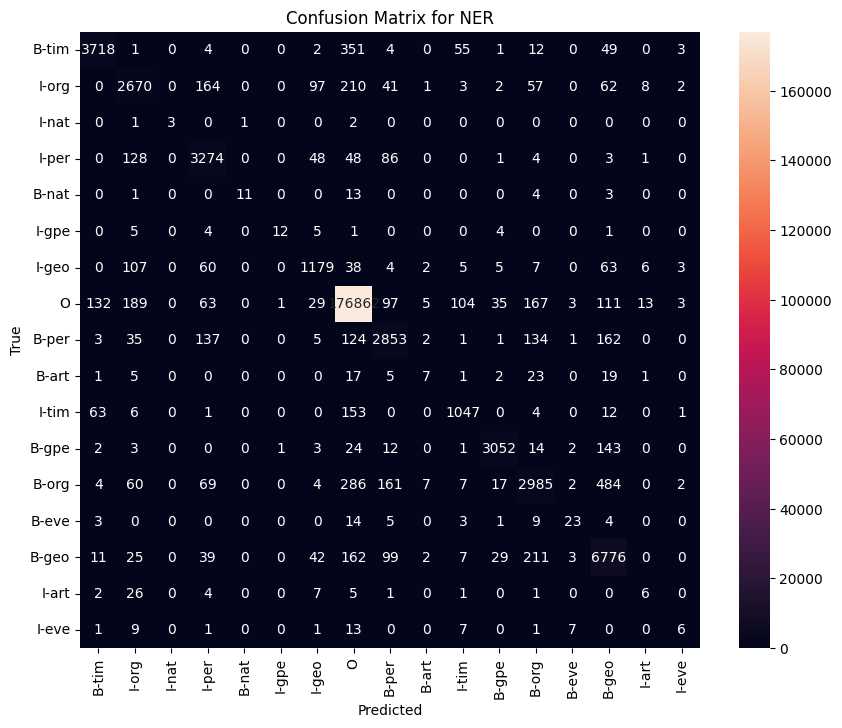

In [57]:
from seqeval.metrics import precision_score, recall_score, f1_score
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np


y_pred = crf.predict(X_test)

print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))


y_test_flat = [tag for seq in y_test for tag in seq]
y_pred_flat = [tag for seq in y_pred for tag in seq]


labels = list({tag for seq in y_test for tag in seq})


cm = confusion_matrix(y_test_flat, y_pred_flat, labels=labels)



plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix for NER")
plt.show()




In [33]:
y_pred[0]

['O',
 'O',
 'O',
 'O',
 'O',
 'O',
 'O',
 'O',
 'O',
 'O',
 'O',
 'O',
 'B-gpe',
 'O',
 'O',
 'O',
 'O',
 'O',
 'O',
 'O']

In [40]:
i=7
for a,b,c in zip(X_test[i],y_pred[i],y_test[i]):
  print (f"mot  :{a['word.lower()']} ,---------------------------- prediction: {b}--------- label: {c}")

mot  :president ,---------------------------- prediction: B-per--------- label: B-per
mot  :bush ,---------------------------- prediction: I-per--------- label: I-per
mot  :is ,---------------------------- prediction: O--------- label: O
mot  :urging ,---------------------------- prediction: O--------- label: O
mot  :senior ,---------------------------- prediction: O--------- label: O
mot  :citizens ,---------------------------- prediction: O--------- label: O
mot  :to ,---------------------------- prediction: O--------- label: O
mot  :enroll ,---------------------------- prediction: O--------- label: O
mot  :in ,---------------------------- prediction: O--------- label: O
mot  :the ,---------------------------- prediction: O--------- label: O
mot  :new ,---------------------------- prediction: O--------- label: O
mot  :medicare ,---------------------------- prediction: B-geo--------- label: B-geo
mot  :prescription ,---------------------------- prediction: O--------- label: O
mot  :dr

Partie C

In [41]:
text

'Thousands of demonstrators have marched through London to protest the war in Iraq and demand the withdrawal of British troops from that country . Families of soldiers killed in the conflict joined the protesters who carried banners with such slogans as " Bush Number One Terrorist " and " Stop the Bombings . " They marched from the Houses of Parliament to a rally in Hyde Park . Police put the number of marchers at 10,000 while organizers claimed it was 1,00,000 . The protest comes on the eve of the annual conference of Britain \'s ruling Labor Party in the southern English seaside resort of Brighton . The party is divided over Britain \'s participation in the Iraq conflict and the continued deployment of 8,500 British troops in that country . The London march came ahead of anti-war protests today in other cities , including Rome , Paris , and Madrid . The International Atomic Energy Agency is to hold second day of talks in Vienna Wednesday on how to respond to Iran \'s resumption of lo

In [42]:
import spacy
from collections import Counter

nlp = spacy.load("en_core_web_sm")
nlp.max_length = 2000000

def top_verbs(text, top_n=10):

    doc = nlp(text)


    verbs = [token.lemma_.lower() for token in doc if token.pos_ == "VERB"]


    verb_counts = Counter(verbs)

    return verb_counts.most_common(top_n)



print(top_verbs(text, top_n=150))



[('say', 466), ('kill', 108), ('have', 48), ('make', 43), ('include', 40), ('call', 40), ('take', 32), ('begin', 30), ('come', 28), ('hold', 26), ('report', 26), ('leave', 24), ('expect', 23), ('arrest', 22), ('accuse', 21), ('show', 21), ('wound', 20), ('tell', 20), ('help', 20), ('allow', 19), ('find', 19), ('know', 19), ('lead', 19), ('die', 19), ('meet', 18), ('release', 18), ('want', 17), ('cause', 17), ('use', 16), ('build', 16), ('be', 16), ('follow', 16), ('run', 16), ('carry', 15), ('end', 15), ('become', 15), ('try', 15), ('stop', 14), ('suspect', 14), ('launch', 14), ('continue', 14), ('reach', 14), ('visit', 14), ('get', 13), ('operate', 13), ('attack', 13), ('sign', 13), ('deny', 13), ('develop', 13), ('claim', 12), ('go', 12), ('give', 12), ('send', 12), ('provide', 12), ('produce', 12), ('rise', 12), ('approve', 12), ('announce', 11), ('speak', 11), ('issue', 11), ('work', 10), ('win', 10), ('base', 10), ('seek', 10), ('do', 10), ('discuss', 10), ('believe', 10), ('retur

In [58]:
df_word=df1.iloc[:30000,:]
text = " ".join(df_word["Word"].astype(str).tolist())


In [60]:
!python -m spacy download en_core_web_md


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 85.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [61]:
import spacy
import networkx as nx
import matplotlib.pyplot as plt



nlp = spacy.load("en_core_web_md", disable=["ner", "textcat"])

nlp.enable_pipe("ner")

nlp.max_length = 3_000_000




top_verbs = {
    'say', 'kill', 'have', 'make', 'include', 'call', 'take', 'begin', 'come', 'hold',
    'report', 'leave', 'expect', 'arrest', 'accuse', 'show', 'wound', 'tell', 'help',
    'allow', 'find', 'know', 'lead', 'die', 'meet', 'release', 'want', 'cause', 'use',
    'build', 'be', 'follow', 'run', 'carry', 'end', 'become', 'try', 'stop', 'suspect',
    'launch', 'continue', 'reach', 'visit', 'get', 'operate', 'attack', 'sign', 'deny',
    'develop', 'claim', 'go', 'give', 'send', 'provide', 'produce', 'rise', 'approve',
    'announce', 'speak', 'issue', 'work', 'win', 'base', 'seek', 'do', 'discuss',
    'believe', 'return', 'prevent', 'warn', 'face', 'detain', 'occur', 'arrive', 'set',
    'serve', 'withdraw', 'capture', 'bring', 'target', 'plan', 'live', 'pay', 'start',
    'fight', 'form', 'remain', 'demand', 'put', 'hit', 'consider', 'order', 'agree',
    'suspend', 'allege', 'recognize', 'suffer', 'reject', 'involve', 'force', 'increase',
    'close', 'enter', 'protest', 'rule', 'aim', 'kidnap', 'fire', 'improve', 'question',
    'shoot', 'hop', 'quote', 'resume', 'accept', 'convict', 'fail', 'protect', 'keep',
    'turn', 'refuse', 'commit', 'charge', 'grow', 'reduce', 'join', 'impose', 'violate',
    'hurt', 'cut', 'raise', 'ask', 'fly', 'injure', 'move', 'open', 'create', 'train',
    'receive', 'add', 'grant', 'blow', 'trigger', 'miss', 'name', 'refer', 'flee', 'see',
    'denounce', 'neighbor'
}




valid_subjects = {"PERSON", "ORG"}
valid_objects = {"PERSON", "ORG", "GPE", "LOC"}




def chunk_text(text, chunk_size=75_000):
    return [text[i:i+chunk_size] for i in range(0, len(text), chunk_size)]




def extract_relations_doc(doc):
    triples = []

    for token in doc:


        if token.pos_ != "VERB":
            continue

        verb = token.lemma_.lower()
        if verb not in top_verbs:
            continue


        subjects = [
            child for child in token.children
            if child.dep_ in ("nsubj", "nsubjpass")
            and child.ent_type_ in valid_subjects
        ]

        if not subjects:
            continue


        objects = [
            child for child in token.children
            if child.dep_ in ("dobj", "attr", "pobj", "dative")
            and child.ent_type_ in valid_objects
        ]


        for prep in [c for c in token.children if c.dep_ == "prep"]:
            for obj in prep.children:
                if obj.ent_type_ in valid_objects:
                    objects.append(obj)

        if not objects:
            continue


        for subj in subjects:
            for obj in objects:
                triples.append((
                    subj.text,
                    verb,
                    obj.text
                ))

    return triples




def extract_relations(text):
    all_triples = []

    for chunk in chunk_text(text):
        doc = nlp(chunk)
        all_triples.extend(extract_relations_doc(doc))

    return all_triples






In [86]:
text_a_tester=df1.iloc[:30000]
text = " ".join(text_a_tester["Word"].astype(str).tolist())

Relations extraites : 22
[('Khayam', 'arrest', 'Bedford'), ('Collins', 'report', 'Sydney'), ('Jiaxuan', 'tell', 'agency'), ('Chavez', 'call', 'Uribe'), ('Ramda', 'operate', 'London'), ('Mwanawasa', 'fly', 'France'), ('Obama', 'name', 'Sperling'), ('Obita', 'tell', 'VOA'), ('Carriles', 'want', 'Venezuela'), ('Karzai', 'meet', 'Obama'), ('Karzai', 'meet', 'Washington'), ('Salazar', 'say', 'Colorado'), ('Rumsfeld', 'visit', 'Mosul'), ('Rostropovich', 'leave', 'Union'), ('Council', 'warn', 'Syria'), ('Clinton', 'face', 'York'), ('Baduel', 'say', 'Caracas'), ('Clinton', 'speak', 'Pakistan'), ('Clinton', 'arrive', 'Islamabad'), ('Asefi', 'tell', 'Tehran')]


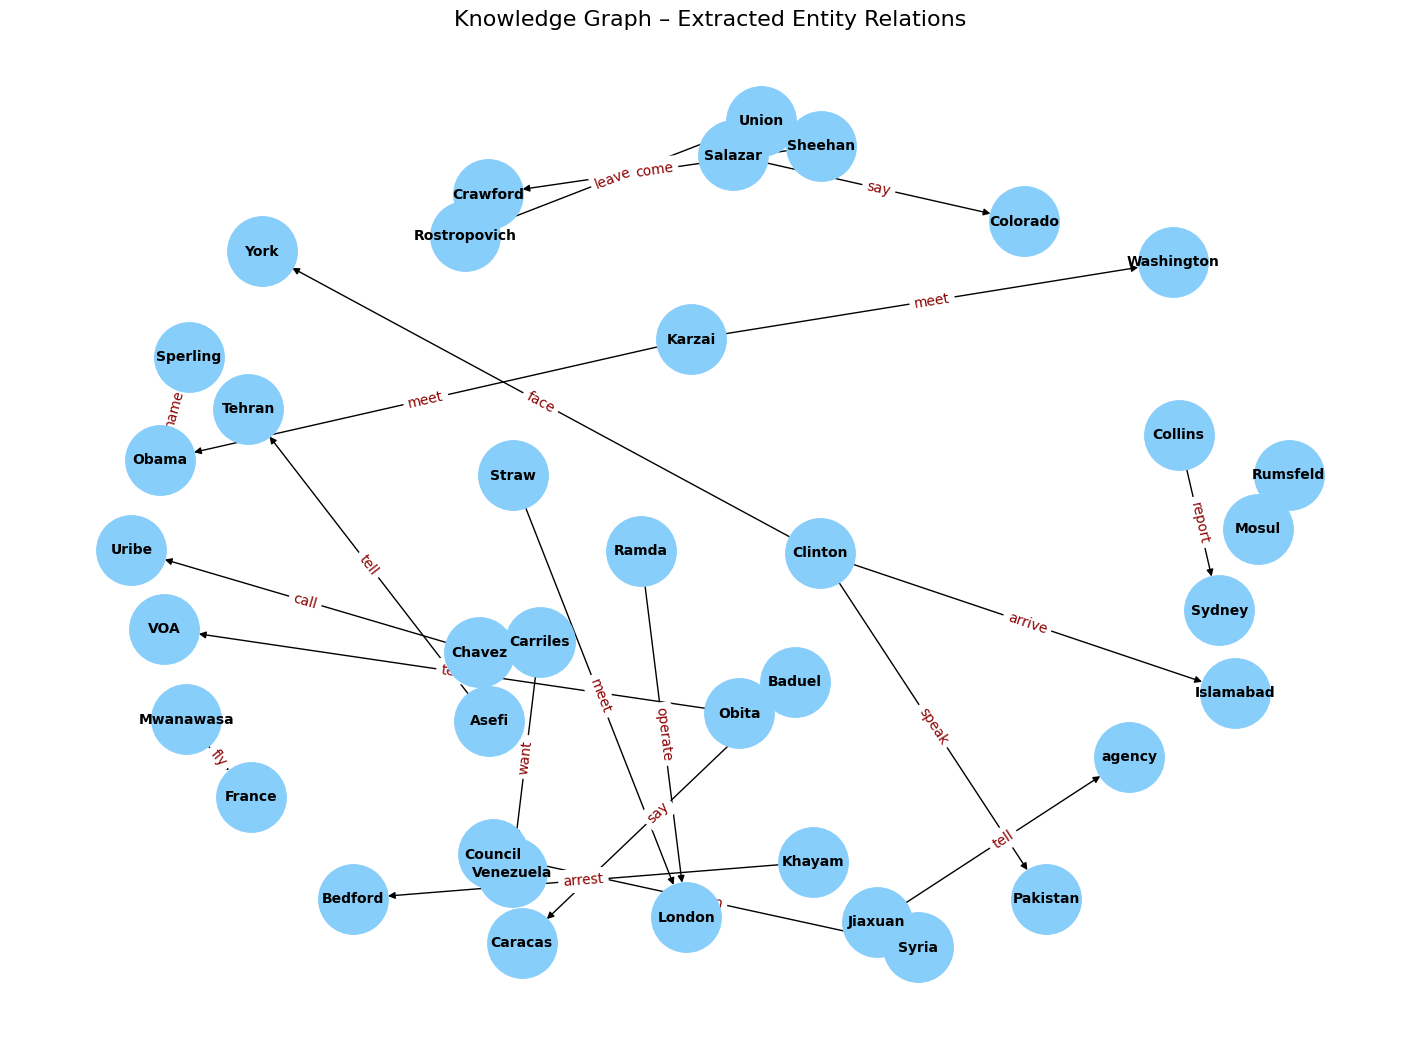

In [87]:
relations = extract_relations(text)
print(f"Relations extraites : {len(relations)}")
print(relations[:20])




G = nx.DiGraph()

for subj, verb, obj in relations:
    G.add_node(subj, type="entity")
    G.add_node(obj, type="entity")
    G.add_edge(subj, obj, label=verb)




plt.figure(figsize=(14,10))
pos = nx.spring_layout(G, k=0.8)

nx.draw(
    G, pos,
    with_labels=True,
    node_color="lightskyblue",
    node_size=2500,
    font_size=10,
    font_weight="bold"
)

edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color="darkred")

plt.title("Knowledge Graph – Extracted Entity Relations", fontsize=16)
plt.show()


In [84]:
"""
Optimized Coreference Resolution for LARGE DOCUMENTS (30000+ words)
- Works sentence by sentence (not whole document)
- Fast and memory efficient
- Handles: he, she, it, they, him, her, them, his, its, their
- Works for: PERSONS, ORGANIZATIONS, LOCATIONS
"""

import spacy
import re
from collections import defaultdict

# Load English spaCy model
nlp = spacy.load('en_core_web_sm')

def split_into_sentences(text):
    """Split text into sentences using spaCy"""
    doc = nlp(text)
    return [sent.text.strip() for sent in doc.sents]


def resolve_sentence(sentence, context_entities=None):
    """
    Resolve coreferences in a SINGLE sentence
    Much faster than processing the whole document at once

    Args:
        sentence: single sentence to process
        context_entities: entities from previous sentences (for context)

    Returns:
        resolved sentence
    """
    doc = nlp(sentence)

    # 1. Extract entities in current sentence
    current_entities = []
    for ent in doc.ents:
        current_entities.append({
            'text': ent.text,
            'label': ent.label_
        })

    # 2. Combine with context entities if provided
    all_entities = current_entities if not context_entities else context_entities + current_entities

    if not all_entities:
        return sentence

    # 3. Group entities by type
    persons = [e['text'] for e in all_entities if e['label'] == 'PERSON']
    orgs = [e['text'] for e in all_entities if e['label'] == 'ORG']
    locations = [e['text'] for e in all_entities if e['label'] in ['GPE', 'LOC']]

    resolved = sentence

    # 4. Replace pronouns based on entity type priority: PERSON > ORG > LOCATION
    if persons:
        if len(persons) > 1:
            main_ref = " and ".join(persons[:2])  # Limit to first 2 for readability
        else:
            main_ref = persons[0]

        # Person pronouns
        replacements = {
            'he': main_ref, 'He': main_ref,
            'she': main_ref, 'She': main_ref,
            'him': main_ref, 'Him': main_ref,
            'her': main_ref, 'Her': main_ref,
            'his': f"{main_ref}'s", 'His': f"{main_ref}'s",
            'they': main_ref, 'They': main_ref,
            'them': main_ref, 'Them': main_ref,
            'their': f"{main_ref}'s", 'Their': f"{main_ref}'s"
        }

    elif orgs:
        main_ref = orgs[0]

        # Organization pronouns
        replacements = {
            'it': main_ref, 'It': main_ref,
            'its': f"{main_ref}'s", 'Its': f"{main_ref}'s",
            'they': main_ref, 'They': main_ref,
            'them': main_ref, 'Them': main_ref,
            'their': f"{main_ref}'s", 'Their': f"{main_ref}'s"
        }

    elif locations:
        main_ref = locations[0]

        # Location pronouns
        replacements = {
            'it': main_ref, 'It': main_ref,
            'its': f"{main_ref}'s", 'Its': f"{main_ref}'s"
        }
    else:
        return sentence

    # 5. Apply replacements (only whole words)
    for pronoun, replacement in replacements.items():
        pattern = r'\b' + re.escape(pronoun) + r'\b'
        resolved = re.sub(pattern, replacement, resolved)

    return resolved


def resolve_document(text, context_window=3):
    """
    Resolve coreferences in a LARGE document efficiently
    Processes sentence by sentence with sliding context window

    Args:
        text: full document text
        context_window: number of previous sentences to consider for context (default=3)

    Returns:
        fully resolved document
    """
    # Split into sentences
    sentences = split_into_sentences(text)
    resolved_sentences = []

    # Track entities from recent sentences (sliding window)
    recent_entities = []

    for i, sentence in enumerate(sentences):
        # Get entities from current sentence
        doc = nlp(sentence)
        current_entities = [{'text': ent.text, 'label': ent.label_} for ent in doc.ents]

        # Resolve using context
        resolved = resolve_sentence(sentence, recent_entities)
        resolved_sentences.append(resolved)

        # Update sliding window of entities
        if current_entities:
            recent_entities.extend(current_entities)
            # Keep only last N sentences of entities
            recent_entities = recent_entities[-context_window * 5:]  # ~5 entities per sentence

    return ' '.join(resolved_sentences)









Relations extraites : 40
[('Khayam', 'arrest', 'Bedford'), ('Collins', 'report', 'Sydney'), ('Java', 'work', 'Mogadishu'), ('Olmert', 'tell', 'Bank'), ('Warner', 'call', 'Bush'), ('Jiaxuan', 'tell', 'agency'), ('Chavez', 'call', 'Uribe'), ('Ramda', 'operate', 'London'), ('Mwanawasa', 'fly', 'France'), ('Obama', 'name', 'Sperling'), ('Obama', 'name', 'Clinton'), ('Obita', 'tell', 'VOA'), ('Abbas', 'fire', 'Israel'), ('Gilani', 'enter', 'Mexico'), ('Carriles', 'want', 'Venezuela'), ('Karzai', 'meet', 'Obama'), ('Karzai', 'meet', 'Washington'), ('Ivanov', 'call', 'Ivanov'), ('Salazar', 'say', 'Colorado'), ('Rumsfeld', 'visit', 'Mosul')]


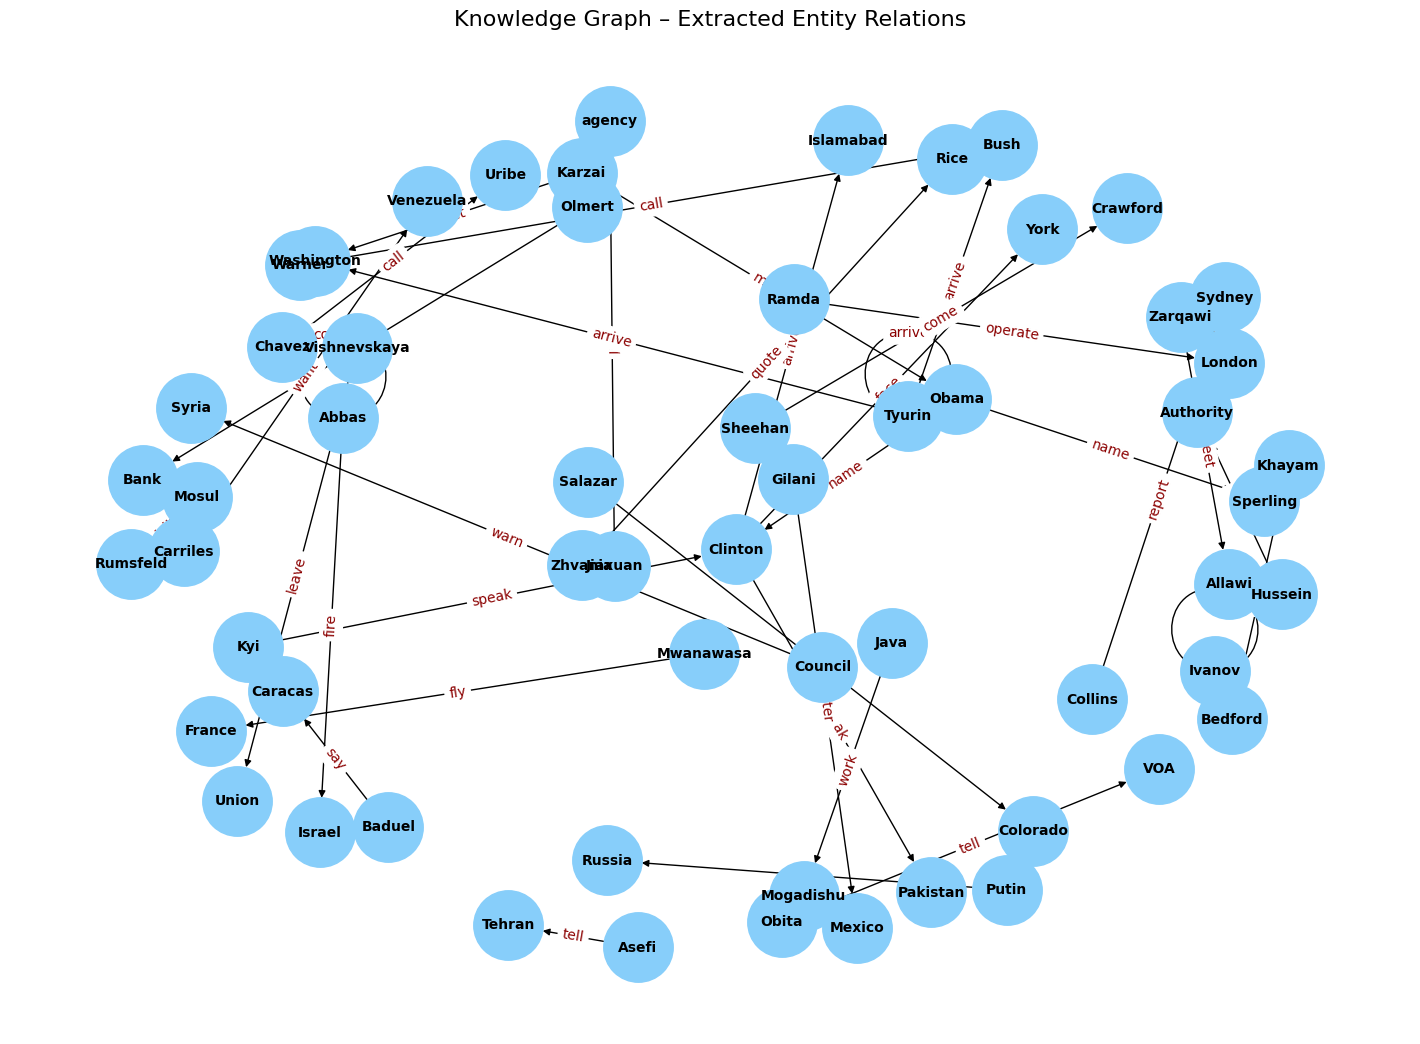

In [88]:
relations = extract_relations(resolve_document(text))
print(f"Relations extraites : {len(relations)}")
print(relations[:20])




G = nx.DiGraph()

for subj, verb, obj in relations:
    G.add_node(subj, type="entity")
    G.add_node(obj, type="entity")
    G.add_edge(subj, obj, label=verb)




plt.figure(figsize=(14,10))
pos = nx.spring_layout(G, k=0.8)

nx.draw(
    G, pos,
    with_labels=True,
    node_color="lightskyblue",
    node_size=2500,
    font_size=10,
    font_weight="bold"
)

edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_color="darkred")

plt.title("Knowledge Graph – Extracted Entity Relations", fontsize=16)
plt.show()


"Obama gave a speech. He named Clinton as Secretary." --> "Obama gave a speech. Obama named Clinton as Secretary."

In [66]:
print(text)

Thousands of demonstrators have marched through London to protest the war in Iraq and demand the withdrawal of British troops from that country . Families of soldiers killed in the conflict joined the protesters who carried banners with such slogans as " Bush Number One Terrorist " and " Stop the Bombings . " They marched from the Houses of Parliament to a rally in Hyde Park . Police put the number of marchers at 10,000 while organizers claimed it was 1,00,000 . The protest comes on the eve of the annual conference of Britain 's ruling Labor Party in the southern English seaside resort of Brighton . The party is divided over Britain 's participation in the Iraq conflict and the continued deployment of 8,500 British troops in that country . The London march came ahead of anti-war protests today in other cities , including Rome , Paris , and Madrid . The International Atomic Energy Agency is to hold second day of talks in Vienna Wednesday on how to respond to Iran 's resumption of low-le

#finetune du model Bert


In [1]:
import json
import pandas as pd

# Function to extract relations from a JSON object
def extract_relations(json_line):
    relations = []
    sent_text = json_line['sentText']
    for relation in json_line['relationMentions']:
        em1_text = relation['em1Text']
        em2_text = relation['em2Text']
        label = relation['label']
        relations.append((sent_text, em1_text, em2_text, label))
    return relations

# Read JSON lines from a file
input_file = '/content/train_2.json'
data = []

with open(input_file, 'r') as file:
    for line in file:
        json_line = json.loads(line)
        relations = extract_relations(json_line)
        data.extend(relations)

# Convert the extracted data to a pandas DataFrame
df = pd.DataFrame(data, columns=['sentence', 'entity1', 'entity2', 'label'])

# Save the DataFrame to a CSV file if needed
output_file = 'extracted_relations.csv'
df.to_csv(output_file, index=False)

df

,sentence,entity1,entity2,label
0,Massachusetts ASTON MAGNA Great Barrington ; a...,Annandale-on-Hudson,Bard College,/location/location/contains
1,North Carolina EASTERN MUSIC FESTIVAL Greensbo...,North Carolina,Greensboro,/location/location/contains
2,It will be the final movie credited to Debra H...,Debra Hill,Haddonfield,/people/person/place_of_birth
3,In a 3-0 victory over the Crew on Saturday in ...,Ohio,Columbus,/location/location/contains
4,"The United States ambassador to Mexico , Tony ...",Mexico,Nuevo Laredo,/location/location/contains
...,...,...,...,...
94217,Here we have a 172-acre island with four-star ...,Manhattan,Ellis Island,/location/location/contains
94218,One was for St. Francis de Sales Roman Catholi...,Belle Harbor,Queens,/location/neighborhood/neighborhood_of
94219,One was for St. Francis de Sales Roman Catholi...,Queens,Rosedale,/location/location/contains
94220,One was for St. Francis de Sales Roman Catholi...,Rosedale,Queens,/location/neighborhood/neighborhood_of


In [2]:
df['label'] = df['label'].str[1:]
df


,sentence,entity1,entity2,label
0,Massachusetts ASTON MAGNA Great Barrington ; a...,Annandale-on-Hudson,Bard College,location/location/contains
1,North Carolina EASTERN MUSIC FESTIVAL Greensbo...,North Carolina,Greensboro,location/location/contains
2,It will be the final movie credited to Debra H...,Debra Hill,Haddonfield,people/person/place_of_birth
3,In a 3-0 victory over the Crew on Saturday in ...,Ohio,Columbus,location/location/contains
4,"The United States ambassador to Mexico , Tony ...",Mexico,Nuevo Laredo,location/location/contains
...,...,...,...,...
94217,Here we have a 172-acre island with four-star ...,Manhattan,Ellis Island,location/location/contains
94218,One was for St. Francis de Sales Roman Catholi...,Belle Harbor,Queens,location/neighborhood/neighborhood_of
94219,One was for St. Francis de Sales Roman Catholi...,Queens,Rosedale,location/location/contains
94220,One was for St. Francis de Sales Roman Catholi...,Rosedale,Queens,location/neighborhood/neighborhood_of


In [3]:
# Change all the forward slashes to underscores in the label column
df['label'] = df['label'].str.replace('/', '_')
df

,sentence,entity1,entity2,label
0,Massachusetts ASTON MAGNA Great Barrington ; a...,Annandale-on-Hudson,Bard College,location_location_contains
1,North Carolina EASTERN MUSIC FESTIVAL Greensbo...,North Carolina,Greensboro,location_location_contains
2,It will be the final movie credited to Debra H...,Debra Hill,Haddonfield,people_person_place_of_birth
3,In a 3-0 victory over the Crew on Saturday in ...,Ohio,Columbus,location_location_contains
4,"The United States ambassador to Mexico , Tony ...",Mexico,Nuevo Laredo,location_location_contains
...,...,...,...,...
94217,Here we have a 172-acre island with four-star ...,Manhattan,Ellis Island,location_location_contains
94218,One was for St. Francis de Sales Roman Catholi...,Belle Harbor,Queens,location_neighborhood_neighborhood_of
94219,One was for St. Francis de Sales Roman Catholi...,Queens,Rosedale,location_location_contains
94220,One was for St. Francis de Sales Roman Catholi...,Rosedale,Queens,location_neighborhood_neighborhood_of


In [4]:
unique_labels = df['label'].unique()
unique_labels

array(['location_location_contains', 'people_person_place_of_birth',
       'business_person_company', 'people_person_place_lived',
       'location_administrative_division_country',
       'location_country_administrative_divisions',
       'people_person_religion', 'people_person_nationality',
       'people_person_children', 'location_country_capital',
       'business_company_place_founded',
       'people_deceased_person_place_of_death',
       'business_company_founders',
       'location_neighborhood_neighborhood_of',
       'business_company_advisors',
       'people_ethnicity_geographic_distribution',
       'sports_sports_team_location_teams', 'sports_sports_team_location',
       'business_company_shareholder_major_shareholder_of',
       'business_company_major_shareholders', 'people_person_ethnicity',
       'people_ethnicity_people', 'people_person_profession',
       'business_company_industry'], dtype=object)

In [5]:
df = df.astype(str)

In [6]:
df.columns


Index(['sentence', 'entity1', 'entity2', 'label'], dtype='object')

In [7]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer, BertForSequenceClassification
from torch.optim import AdamW
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(df, test_size=0.2, random_state=42)

# 1. Preprocess the data
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
label_encoder = {label: i for i, label in enumerate(df['label'].unique())}
def preprocess_data(row):
    sentence = row['sentence']
    entity1 = row['entity1']
    entity2 = row['entity2']

    # Tokenize sentence
    tokens = tokenizer.tokenize(sentence)

    # Find positions of entities in tokenized sentence
    entity1_pos = [i for i, token in enumerate(tokens) if token in tokenizer.tokenize(entity1)]
    entity2_pos = [i for i, token in enumerate(tokens) if token in tokenizer.tokenize(entity2)]

    # Encode entities positions
    encoded_sentence = tokenizer.encode_plus(
        sentence,
        add_special_tokens=True,
        max_length=128,
        padding='max_length',
        truncation=True,
        return_attention_mask=True,
        return_tensors='pt'
    )

    return {
        'input_ids': encoded_sentence['input_ids'].squeeze(),
        'attention_mask': encoded_sentence['attention_mask'].squeeze(),
        'entity1_pos': torch.tensor(entity1_pos[0] if entity1_pos else 0),
        'entity2_pos': torch.tensor(entity2_pos[0] if entity2_pos else 0),
        'label': torch.tensor(label_encoder[row['label']])
    }

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

In [8]:
train_data = train_df.apply(preprocess_data, axis=1).tolist()
val_data = val_df.apply(preprocess_data, axis=1).tolist()

In [24]:
class RelationshipDataset(Dataset):
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]

# Create dataset and dataloader
train_dataset = RelationshipDataset(train_data)
val_dataset = RelationshipDataset(val_data)
train_dataloader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=16, shuffle=False)

In [25]:
class RelationshipExtractionModel(torch.nn.Module):
    def __init__(self, num_labels):
        super().__init__()
        self.bert = BertForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=num_labels)

    def forward(self, input_ids, attention_mask, entity1_pos, entity2_pos):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits
        return logits

In [26]:
num_labels = len(df['label'].unique())
model = RelationshipExtractionModel(num_labels)
optimizer = AdamW(model.parameters(), lr=2e-5)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [27]:
num_epochs = 5
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)

RelationshipExtractionModel(
  (bert): BertForSequenceClassification(
    (bert): BertModel(
      (embeddings): BertEmbeddings(
        (word_embeddings): Embedding(30522, 768, padding_idx=0)
        (position_embeddings): Embedding(512, 768)
        (token_type_embeddings): Embedding(2, 768)
        (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (encoder): BertEncoder(
        (layer): ModuleList(
          (0-11): 12 x BertLayer(
            (attention): BertAttention(
              (self): BertSdpaSelfAttention(
                (query): Linear(in_features=768, out_features=768, bias=True)
                (key): Linear(in_features=768, out_features=768, bias=True)
                (value): Linear(in_features=768, out_features=768, bias=True)
                (dropout): Dropout(p=0.1, inplace=False)
              )
              (output): BertSelfOutput(
                (dense): Linear(in_features=768, o

In [28]:
from sklearn.metrics import accuracy_score
def evaluate(model, dataloader):
    model.eval()
    total_preds = []
    total_labels = []

    with torch.no_grad():
        for batch in dataloader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            entity1_pos = batch['entity1_pos'].to(device)
            entity2_pos = batch['entity2_pos'].to(device)
            labels = batch['label'].to(device)

            outputs = model(input_ids, attention_mask, entity1_pos, entity2_pos)
            _, preds = torch.max(outputs, dim=1)

            total_preds.extend(preds.cpu().tolist())
            total_labels.extend(labels.cpu().tolist())

    return accuracy_score(total_labels, total_preds)

In [29]:
from tqdm.auto import tqdm

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    progress_bar = tqdm(train_dataloader, desc=f"Epoch {epoch+1}/{num_epochs}")

    for batch in progress_bar:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        entity1_pos = batch['entity1_pos'].to(device)
        entity2_pos = batch['entity2_pos'].to(device)
        labels = batch['label'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids, attention_mask, entity1_pos, entity2_pos)
        loss = torch.nn.functional.cross_entropy(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        progress_bar.set_postfix({'loss': total_loss / (progress_bar.n + 1)})

    # Calculate validation accuracy
    val_accuracy = evaluate(model, val_dataloader)
    print(f"Epoch {epoch+1}/{num_epochs} completed. Validation Accuracy: {val_accuracy:.4f}")

Epoch 1/5:   0%|          | 0/4712 [00:00<?, ?it/s]

Epoch 1/5 completed. Validation Accuracy: 0.6524


Epoch 2/5:   0%|          | 0/4712 [00:00<?, ?it/s]

Epoch 2/5 completed. Validation Accuracy: 0.6580


Epoch 3/5:   0%|          | 0/4712 [00:00<?, ?it/s]

Epoch 3/5 completed. Validation Accuracy: 0.6539


Epoch 4/5:   0%|          | 0/4712 [00:00<?, ?it/s]

Epoch 4/5 completed. Validation Accuracy: 0.6602


Epoch 5/5:   0%|          | 0/4712 [00:00<?, ?it/s]

Epoch 5/5 completed. Validation Accuracy: 0.6408


In [36]:
import spacy
import torch
from itertools import combinations


nlp = spacy.load("en_core_web_sm")


def extract_entity_pairs(text):
    doc = nlp(text)
    sentences = list(doc.sents)
    all_pairs = []

    for sent in sentences:
        sent_text = sent.text
        entities = [(ent.text, ent.label_) for ent in sent.ents]
        # On ne garde que les entités nommées pertinentes (PERSON, ORG, LOC, GPE, etc.)
        if len(entities) < 2:
            continue
        # Toutes les paires possibles d'entités
        for (e1, l1), (e2, l2) in combinations(entities, 2):
            all_pairs.append({
                "sentence": sent_text,
                "entity1": e1,
                "entity2": e2
            })
    return all_pairs

# 3️⃣ Fonction pour préparer le batch pour BERT
def prepare_batch(pair, tokenizer, label_encoder, max_length=128):
    sentence = pair["sentence"]
    e1 = pair["entity1"]
    e2 = pair["entity2"]

    # Optionnel : ajouter des tokens spéciaux autour des entités
    sentence_marked = sentence.replace(e1, f"<e1> {e1} </e1>", 1)
    sentence_marked = sentence_marked.replace(e2, f"<e2> {e2} </e2>", 1)

    encoded = tokenizer.encode_plus(
        sentence_marked,
        add_special_tokens=True,
        max_length=max_length,
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    )

    return {
        "input_ids": encoded["input_ids"].to(device),
        "attention_mask": encoded["attention_mask"].to(device),
        "entity1_pos": torch.tensor([0]).to(device),  # Si tu veux utiliser entity pos
        "entity2_pos": torch.tensor([0]).to(device)
    }

# 4️⃣ Pipeline pour prédire toutes les relations dans un texte
def predict_relations(text, model, tokenizer, label_encoder):
    model.eval()
    pairs = extract_entity_pairs(text)
    predictions = []

    for pair in pairs:
        batch = prepare_batch(pair, tokenizer, label_encoder)
        with torch.no_grad():
            logits = model(batch["input_ids"], batch["attention_mask"], batch["entity1_pos"], batch["entity2_pos"])
            pred_label_idx = torch.argmax(logits, dim=1).item()
            pred_label = list(label_encoder.keys())[list(label_encoder.values()).index(pred_label_idx)]

        predictions.append({
            "entity1": pair["entity1"],
            "entity2": pair["entity2"],
            "sentence": pair["sentence"],
            "relation": pred_label
        })
    return predictions



preds = predict_relations(text, model, tokenizer, label_encoder)



{'entity1': 'Thousands', 'entity2': 'London', 'sentence': 'Thousands of demonstrators have marched through London to protest the war in Iraq and demand the withdrawal of British troops from that country .', 'relation': 'location_location_contains'}
{'entity1': 'Thousands', 'entity2': 'Iraq', 'sentence': 'Thousands of demonstrators have marched through London to protest the war in Iraq and demand the withdrawal of British troops from that country .', 'relation': 'location_location_contains'}
{'entity1': 'Thousands', 'entity2': 'British', 'sentence': 'Thousands of demonstrators have marched through London to protest the war in Iraq and demand the withdrawal of British troops from that country .', 'relation': 'location_location_contains'}
{'entity1': 'London', 'entity2': 'Iraq', 'sentence': 'Thousands of demonstrators have marched through London to protest the war in Iraq and demand the withdrawal of British troops from that country .', 'relation': 'location_location_contains'}
{'entity1'

In [37]:
print(len(preds))

6045


In [38]:
for p in preds:
    print(p["entity1"], '------', p["entity2"], '------', p["relation"])

Thousands ------ London ------ location_location_contains
Thousands ------ Iraq ------ location_location_contains
Thousands ------ British ------ location_location_contains
London ------ Iraq ------ location_location_contains
London ------ British ------ location_location_contains
Iraq ------ British ------ location_location_contains
the Houses of Parliament ------ Hyde Park ------ location_location_contains
10,000 ------ 1,00,000 ------ business_company_place_founded
annual ------ Britain ------ location_location_contains
annual ------ Labor Party ------ location_location_contains
annual ------ English ------ location_location_contains
annual ------ Brighton ------ location_location_contains
Britain ------ Labor Party ------ location_location_contains
Britain ------ English ------ location_location_contains
Britain ------ Brighton ------ location_location_contains
Labor Party ------ English ------ location_location_contains
Labor Party ------ Brighton ------ location_location_contains

In [89]:
import pandas as pd

df = pd.read_csv("hf://datasets/knowledgator/sentence_rex/train.csv")

In [93]:
df["labels"].unique()

array(['canonization status', 'this taxon is source of', 'librettist',
       'grants', 'next crossing upstream',
       'drug or therapy used for treatment', 'wing configuration',
       'lake outflow', 'domain of saint or deity', 'voice type',
       'constellation', 'board member', 'convicted of', 'collection',
       'highest point', 'powered by', 'vessel class', 'model item',
       'parent club', 'victim', 'medical condition treated',
       'competition class', 'parent astronomical body',
       'chief executive officer', 'incarnation of', 'filming location',
       'speaker', 'has works in the collection', 'expressed in',
       'currency', 'operating area', 'target',
       'office held by head of the organization', 'nominee',
       'location of first performance', 'musical conductor',
       'series spin-off', 'architectural style', 'structural engineer',
       'commissioned by', 'carries', 'risk factor', 'reservoir created',
       'has boundary', 'minor planet group', 'wo

le resultats avec le fintune de Bert n'est pas bon du tout

In [96]:
import json
import pandas as pd

# Charger le JSON
with open("/content/train_annotated.json", "r") as f:
    data = json.load(f)

examples = []

for doc in data:
    vertex_set = doc["vertexSet"]
    sents = doc["sents"]
    labels = doc.get("labels", [])

    entities = {i: ent for i, ents in enumerate(vertex_set) for ent in ents}

    for label in labels:
        head = entities[label["h"]]["name"]
        tail = entities[label["t"]]["name"]
        relation = label["r"]
        evidence_sents = [sents[eid] for eid in label["evidence"]]
        sentence_text = " ".join([token for sent in evidence_sents for token in sent])

        examples.append({
            "sentence": sentence_text,
            "entity1": head,
            "entity2": tail,
            "label": relation
        })

df = pd.DataFrame(examples)
print(df.head())


                                            sentence       entity1  \
0  Zest Airways , Inc. operated as AirAsia Zest (...  AirAsia Zest   
1  In 2013 , the airline became an affiliate of P...  AirAsia Zest   
2  Less than a year after AirAsia and Zest Air 's...      Zest Air   
3  Zest Airways , Inc. operated as AirAsia Zest (...    Pasay City   
4  Zest Airways , Inc. operated as AirAsia Zest (...    Pasay City   

                       entity2 label  
0                   Pasay City  P159  
1  Republic of the Philippines   P17  
2  Republic of the Philippines   P17  
3  Republic of the Philippines   P17  
4                 Metro Manila  P131  


In [99]:
from collections import Counter
from sklearn.preprocessing import LabelEncoder
import torch

# Construire le vocabulaire
all_tokens = [token for sent in df['sentence'] for token in sent.split()]
vocab = {"<PAD>":0, "<UNK>":1}
for i, word in enumerate(set(all_tokens), start=2):
    vocab[word] = i

def encode_sentence(sentence, vocab, max_len=100):
    tokens = sentence.split()
    seq = [vocab.get(token, vocab["<UNK>"]) for token in tokens]
    if len(seq) < max_len:
        seq += [vocab["<PAD>"]] * (max_len - len(seq))
    else:
        seq = seq[:max_len]
    return seq

X_pad = torch.tensor([encode_sentence(s, vocab) for s in df['sentence']], dtype=torch.long)

# Encoder les labels
le = LabelEncoder()
y = torch.tensor(le.fit_transform(df['label']), dtype=torch.long)
num_classes = len(le.classes_)


In [100]:
import torch
from torch.utils.data import Dataset, DataLoader

class RelationDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

dataset = RelationDataset(X_pad, y)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)


/tmp/ipython-input-1619464725.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.X = torch.tensor(X, dtype=torch.long)
/tmp/ipython-input-1619464725.py:7: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.y = torch.tensor(y, dtype=torch.long)


In [160]:
import json
import pandas as pd

# =========================
# 1️⃣ Charger et préparer le dataset (CORRIGÉ)
# =========================

examples = []

file_path = "/content/train_distant.json"

# Charger tout le fichier JSON
with open(file_path, "r", encoding="utf-8") as f:
    text = f.read()

try:
    data = json.loads(text)
except json.JSONDecodeError as e:
    print("Erreur JSON :", e)
    data = []

# Parcours des documents DocRED
for doc in data:
    vertex_set = doc["vertexSet"]   # clusters d'entités
    sents = doc["sents"]            # phrases tokenisées
    labels = doc.get("labels", [])  # relations

    for label in labels:
        h_idx = label["h"]
        t_idx = label["t"]
        relation = label["r"]

        # ✅ Prendre UNE mention canonique par entité (PAS flatten)
        head = vertex_set[h_idx][0]["name"]
        tail = vertex_set[t_idx][0]["name"]

        evidence_ids = label.get("evidence", [])

        # ✅ Si evidence existe → on l'utilise
        if evidence_ids:
            used_sents = [sents[i] for i in evidence_ids if i < len(sents)]
        else:
            # ✅ Fallback : phrases contenant head ou tail
            used_sents = []
            for sent in sents:
                sent_text = " ".join(sent)
                if head in sent_text or tail in sent_text:
                    used_sents.append(sent)

        # Sécurité : ignorer si toujours vide
        if not used_sents:
            continue

        sentence_text = " ".join(
            token for sent in used_sents for token in sent
        )

        examples.append({
            "sentence": sentence_text,
            "entity1": head,
            "entity2": tail,
            "label": relation
        })

# Construire le DataFrame
df = pd.DataFrame(examples)

print("Nombre d'exemples :", len(df))
print(df.head())


Nombre d'exemples : 1501001
                                            sentence  \
0  The Worker - Peasant Red Guards ( WPRG ; ) , a...   
1  The Worker - Peasant Red Guards ( WPRG ; ) , a...   
2  The Worker - Peasant Red Guards ( WPRG ; ) , a...   
3  It was established on January 14 , 1959 by Kim...   
4  It was established on January 14 , 1959 by Kim...   

                    entity1                      entity2  label  
0               North Korea                  Kim Il-sung    P35  
1               Kim Il-sung                  North Korea    P27  
2  State Affairs Commission                  North Korea    P17  
3  State Affairs Commission                         2016   P571  
4  State Affairs Commission  National Defense Commission  P1365  


In [162]:
df.iloc[0]['sentence']

"The Worker - Peasant Red Guards ( WPRG ; ) , also translated as Workers and Peasants ' Red Militia ( WPRM ) , is a paramilitary force in North Korea . It is the largest civil defense force in North Korea ."

In [184]:
# =========================================================
# 0️⃣ Imports
# =========================================================

import json
import re
import pandas as pd
import numpy as np
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, f1_score

# =========================================================
# 1️⃣ Charger et préparer le dataset DocRED
# =========================================================
examples = []

with open("/content/train_distant.json", "r") as f:
    data = json.load(f)

for doc in data:
    sents = doc["sents"]
    vertex_set = doc["vertexSet"]
    labels = doc.get("labels", [])

    # mapping entités
    entities = {
        i: ents[0]["name"]
        for i, ents in enumerate(vertex_set)
    }

    # concat de TOUT le document
    full_doc_text = " ".join([" ".join(sent) for sent in sents])

    for lab in labels:
        h, t = lab["h"], lab["t"]
        relation = lab["r"]

        evidence = lab.get("evidence", [])

        # 👉 CORRECTION CLÉ
        if evidence:
            sentence = " ".join(
                [" ".join(sents[i]) for i in evidence]
            )
        else:
            sentence = full_doc_text  # fallback

        examples.append({
            "sentence": sentence,
            "entity1": entities[h],
            "entity2": entities[t],
            "label": relation
        })

df = pd.DataFrame(examples)

# Sécurité
df = df[df["sentence"].str.strip() != ""]

print("Exemples valides :", len(df))
print(df.head())




Exemples valides : 1505638
                                            sentence  \
0  The Worker - Peasant Red Guards ( WPRG ; ) , a...   
1  The Worker - Peasant Red Guards ( WPRG ; ) , a...   
2  The Worker - Peasant Red Guards ( WPRG ; ) , a...   
3  The Worker - Peasant Red Guards ( WPRG ; ) , a...   
4  The Worker - Peasant Red Guards ( WPRG ; ) , a...   

                    entity1                  entity2 label  
0               North Korea              Kim Il-sung   P35  
1               Kim Il-sung              North Korea   P27  
2               Kim Il-sung  Workers' Party of Korea  P102  
3  State Affairs Commission              North Korea   P17  
4  State Affairs Commission                     2016  P571  


In [185]:
df_bcp=df.copy()

In [229]:
df=df_bcp[:300000]
df

,sentence,entity1,entity2,label
0,"The Worker - Peasant Red Guards ( WPRG ; ) , a...",North Korea,Kim Il-sung,P35
1,"The Worker - Peasant Red Guards ( WPRG ; ) , a...",Kim Il-sung,North Korea,P27
2,"The Worker - Peasant Red Guards ( WPRG ; ) , a...",Kim Il-sung,Workers' Party of Korea,P102
3,"The Worker - Peasant Red Guards ( WPRG ; ) , a...",State Affairs Commission,North Korea,P17
4,"The Worker - Peasant Red Guards ( WPRG ; ) , a...",State Affairs Commission,2016,P571
...,...,...,...,...
299995,"Gun - Marie Fredriksson , known as ( born 30 M...",Roxette,1986,P571
299996,"Gun - Marie Fredriksson , known as ( born 30 M...",Per Gessle,Roxette,P361
299997,"Gun - Marie Fredriksson , known as ( born 30 M...",Per Gessle,Roxette,P463
299998,"Gun - Marie Fredriksson , known as ( born 30 M...",It Must Have Been Love,Roxette,P175


In [230]:
# =========================================================
# 0️⃣ Imports
# =========================================================
import json
import re
import pandas as pd
import numpy as np
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, f1_score
from sklearn.utils.class_weight import compute_class_weight



# =========================================================
# 2️⃣ Entity Markers
# =========================================================
def mark_entities(sentence, e1, e2):
    sentence = sentence.replace(e1, f"<E1> {e1} </E1>")
    sentence = sentence.replace(e2, f"<E2> {e2} </E2>")
    return sentence

df["sentence"] = df.apply(
    lambda x: mark_entities(x["sentence"], x["entity1"], x["entity2"]),
    axis=1
)

# =========================================================
# 3️⃣ Tokenisation & Vocabulaire
# =========================================================
def tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())

counter = Counter()
for sent in df["sentence"]:
    counter.update(tokenize(sent))

vocab = {
    "<PAD>": 0, "<UNK>": 1,
    "<E1>": 2, "</E1>": 3,
    "<E2>": 4, "</E2>": 5
}
for word in counter:
    if word not in vocab:
        vocab[word] = len(vocab)

def encode_sentence(sentence, max_len=120):
    tokens = tokenize(sentence)
    seq = [vocab.get(tok, vocab["<UNK>"]) for tok in tokens]
    if len(seq) < max_len:
        seq += [vocab["<PAD>"]] * (max_len - len(seq))
    else:
        seq = seq[:max_len]
    return seq

X = torch.tensor([encode_sentence(s) for s in df["sentence"]], dtype=torch.long)

# =========================================================
# 4️⃣ Encodage des labels
# =========================================================
le = LabelEncoder()
y = torch.tensor(le.fit_transform(df["label"]), dtype=torch.long)
num_classes = len(le.classes_)

print("Nombre de classes :", num_classes)

# =========================================================
# 5️⃣ Dataset & DataLoader
# =========================================================
class RelationDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

dataset = RelationDataset(X, y)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)

# =========================================================
# 6️⃣ BiLSTM + Entity-Aware Attention
# =========================================================
class BiLSTMEntityAttention(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.dropout = nn.Dropout(0.3)
        self.bilstm = nn.LSTM(
            embed_dim,
            hidden_dim,
            num_layers=3,
            batch_first=True,
            bidirectional=True,
            dropout=0.3
        )

        self.attention = nn.Linear(hidden_dim * 2, hidden_dim)
        self.context_vector = nn.Linear(hidden_dim, 1, bias=False)

        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim * 6, 512),  # ⚠️ hidden_dim*6 pour concat [sent, e1, e2]
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        emb = self.dropout(self.embedding(x))
        lstm_out, _ = self.bilstm(emb)  # (B, T, 2H)

        # Masks pour les entités
        e1_mask = (x == vocab["<E1>"]).unsqueeze(-1)
        e2_mask = (x == vocab["<E2>"]).unsqueeze(-1)

        e1_repr = torch.sum(lstm_out * e1_mask, dim=1)
        e2_repr = torch.sum(lstm_out * e2_mask, dim=1)

        # Attention entity-aware
        attn_hidden = torch.tanh(self.attention(lstm_out))
        attn_scores = self.context_vector(attn_hidden)
        attn_scores += (e1_mask.float() + e2_mask.float()) * 3.0
        attn_weights = F.softmax(attn_scores, dim=1)
        sent_repr = torch.sum(attn_weights * lstm_out, dim=1)

        # Concatenation finale
        final_repr = torch.cat([sent_repr, e1_repr, e2_repr], dim=1)
        return self.classifier(final_repr)

# =========================================================
# 7️⃣ Entraînement
# =========================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BiLSTMEntityAttention(
    vocab_size=len(vocab),
    embed_dim=300,
    hidden_dim=512,
    num_classes=num_classes
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

class_weights = compute_class_weight(
    'balanced',
    classes=np.unique(y.numpy()),
    y=y.numpy()
)

criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float).to(device)
)

epochs = 10

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/{epochs} - Loss: {total_loss/len(train_loader):.4f}")

# =========================================================
# 8️⃣ Évaluation
# =========================================================
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for xb, yb in val_loader:
        xb, yb = xb.to(device), yb.to(device)
        preds = torch.argmax(model(xb), dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(yb.cpu().numpy())

print(classification_report(
    all_labels,
    all_preds,
    labels=np.arange(num_classes),
    target_names=le.classes_,
    zero_division=0
))

print("Macro F1 :", f1_score(all_labels, all_preds, average="macro"))
print("Micro F1 :", f1_score(all_labels, all_preds, average="micro"))


/tmp/ipython-input-276301167.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["sentence"] = df.apply(


Nombre de classes : 96
Epoch 1/10 - Loss: 3.6233
Epoch 2/10 - Loss: 2.2196
Epoch 3/10 - Loss: 1.8388
Epoch 4/10 - Loss: 1.6487
Epoch 5/10 - Loss: 1.5440
Epoch 6/10 - Loss: 1.4636
Epoch 7/10 - Loss: 1.4131
Epoch 8/10 - Loss: 1.3697
Epoch 9/10 - Loss: 1.3314
Epoch 10/10 - Loss: 1.3164
              precision    recall  f1-score   support

       P1001       0.12      0.72      0.20       371
        P102       0.55      0.81      0.65       458
       P1056       0.44      0.64      0.52        25
        P108       0.36      0.43      0.39       280
        P112       0.48      0.33      0.39       315
        P118       0.69      0.96      0.80       246
       P1198       0.12      0.70      0.20        60
        P123       0.47      0.75      0.58       182
        P127       0.24      0.12      0.16       306
        P131       0.76      0.43      0.55      5906
       P1336       0.23      0.71      0.35        65
       P1344       0.46      0.82      0.59       126
        P136 

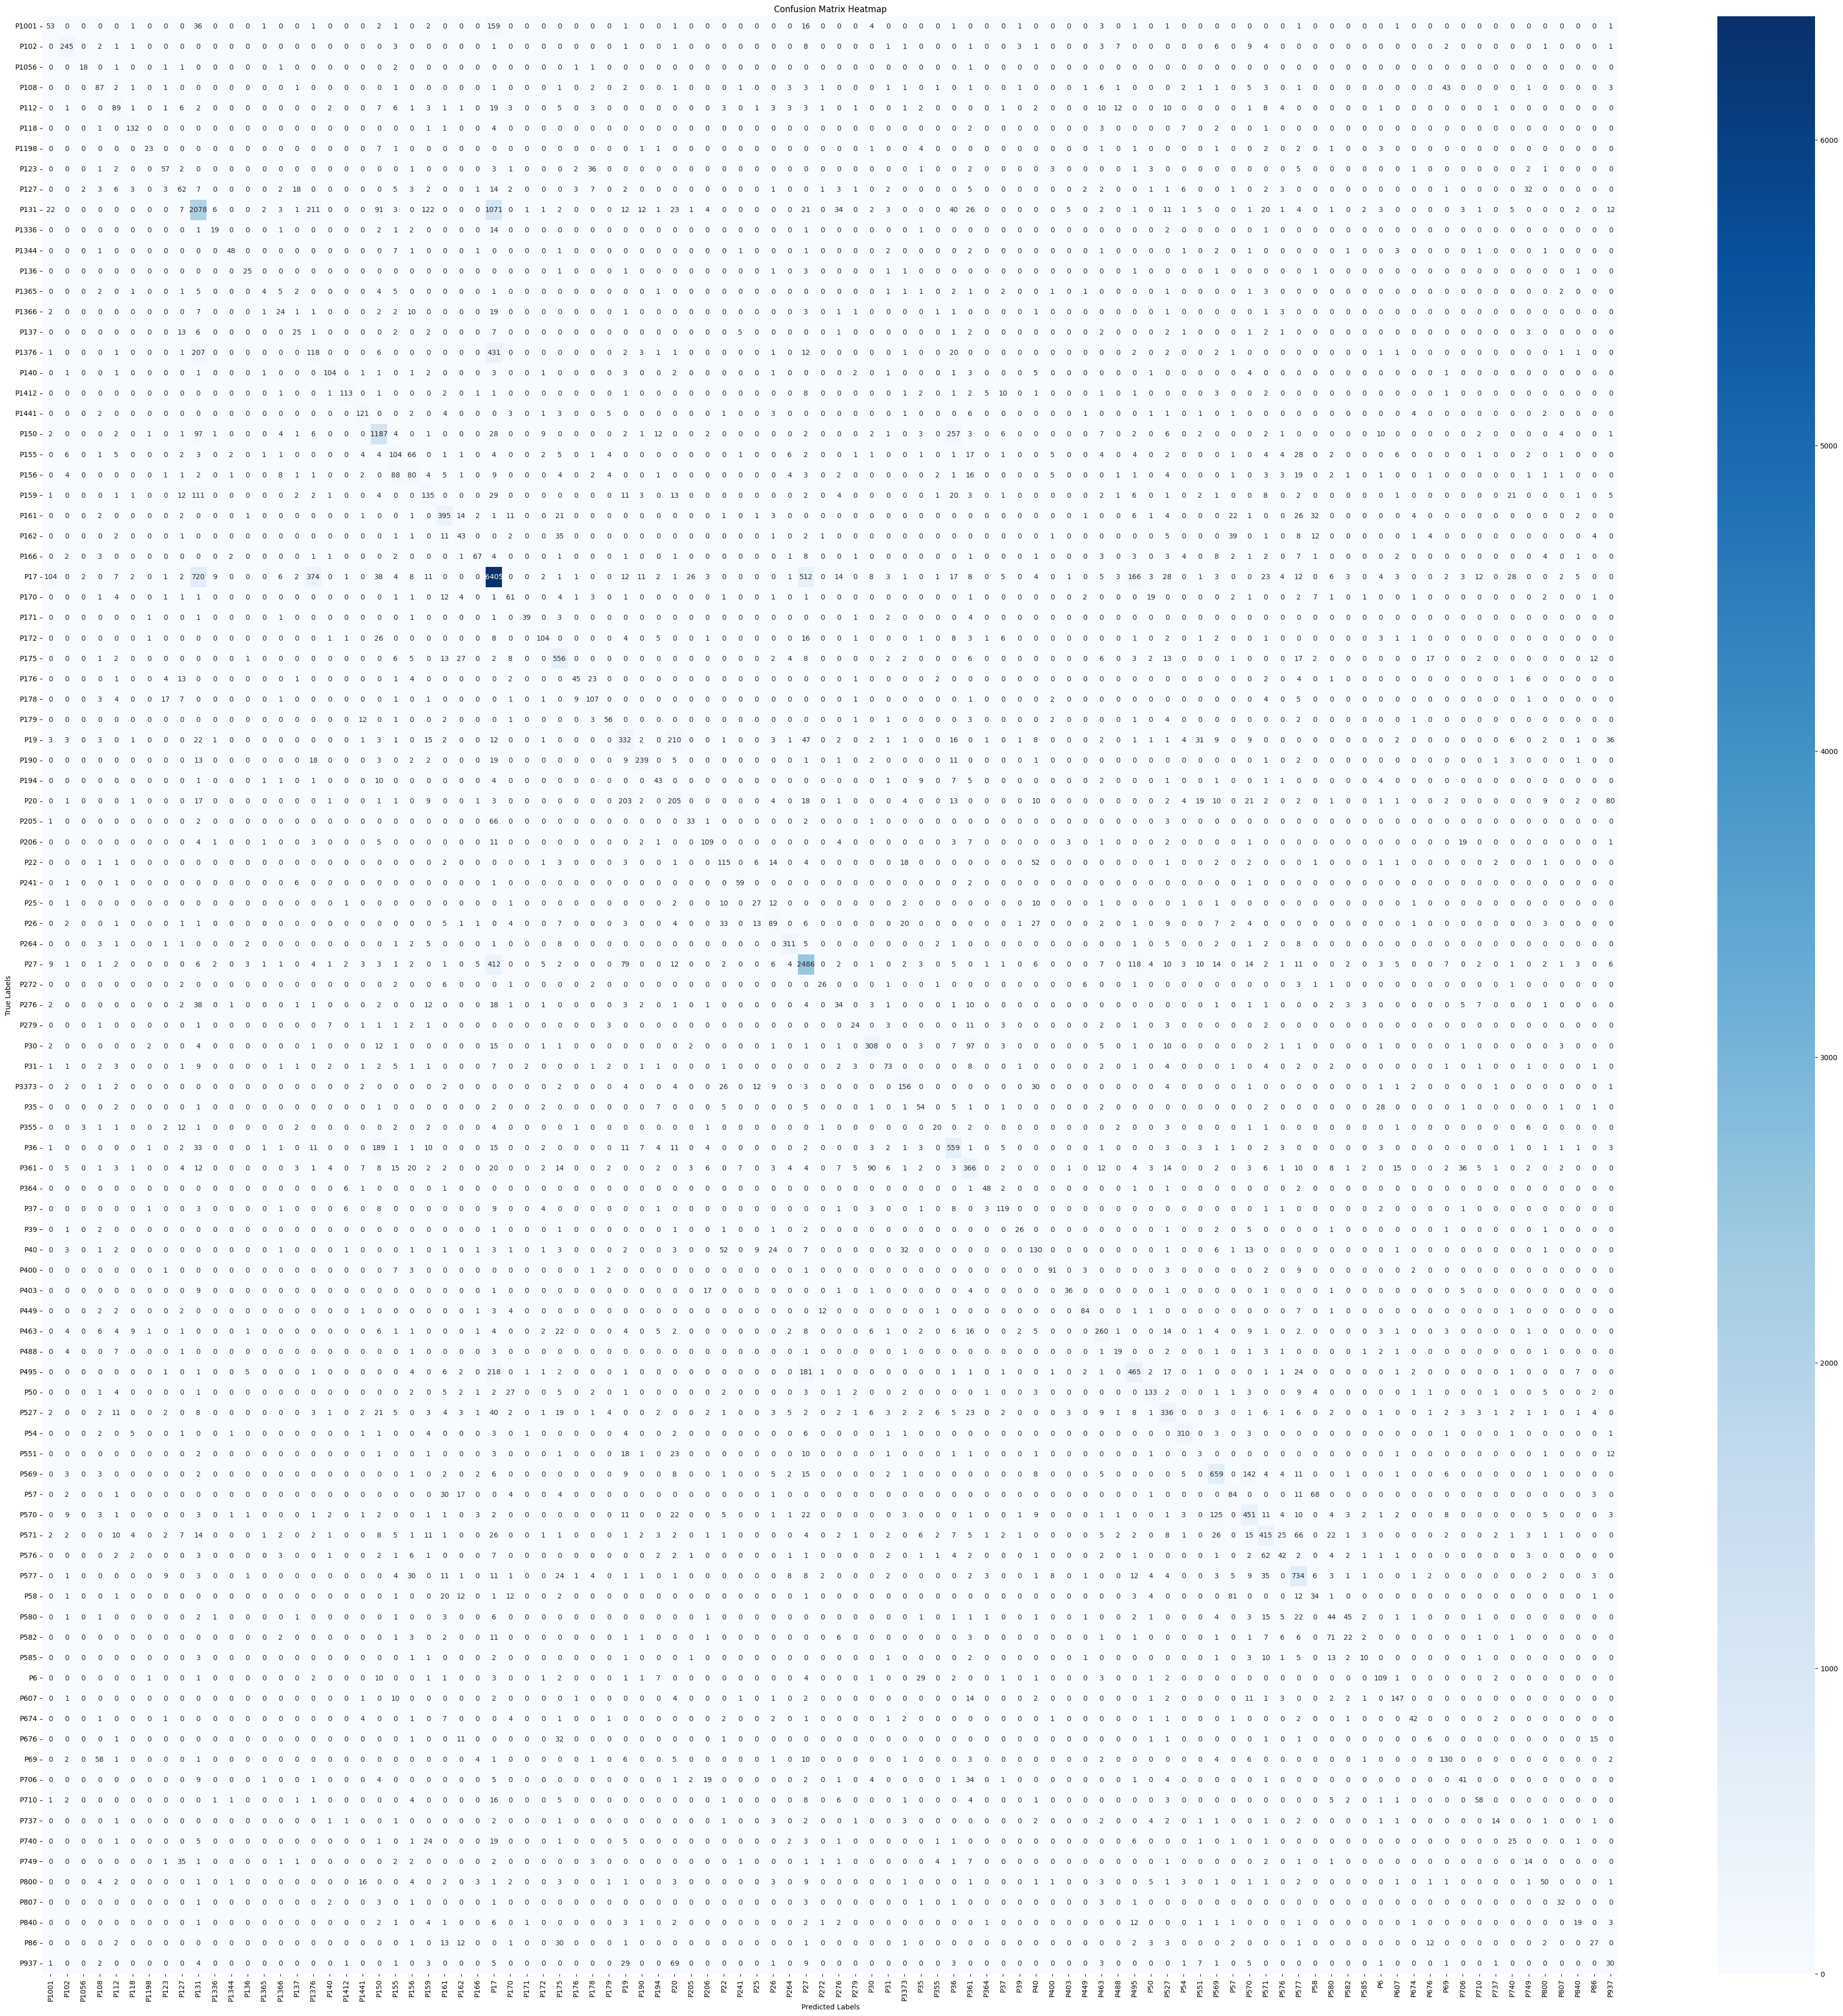

In [210]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# =========================
# 1️⃣ Calculer la matrice de confusion
# =========================
cm = confusion_matrix(all_labels, all_preds, labels=np.arange(len(le.classes_)))

# =========================
# 2️⃣ Créer la heatmap
# =========================
plt.figure(figsize=(50, (50)))  # Ajuste la taille selon le nombre de classes
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix Heatmap")
plt.show()


un tres grand dans les données (entre la class P17 et les autres)

In [231]:


def predict_relation(sentence, entity1, entity2, model, vocab, label_encoder, max_len=100):
    model.eval()

    # Marquer les entités comme à l'entraînement
    sentence = sentence.replace(entity1, f"<E1> {entity1} </E1>")
    sentence = sentence.replace(entity2, f"<E2> {entity2} </E2>")

    tokens = sentence.split()
    seq = [vocab.get(tok, vocab["<UNK>"]) for tok in tokens]
    seq = seq[:max_len] + [vocab["<PAD>"]] * max(0, max_len - len(seq))

    x = torch.tensor(seq).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(x)
        pred = torch.argmax(logits, dim=1).item()

    return label_encoder.inverse_transform([pred])[0]


# =========================
# 🎯 EXEMPLE POLITIQUE
# =========================

sentence = "Jhon is the father of Jack"
entity1 = "Jhon"
entity2 = "Jack"

predicted_relation = predict_relation(
    sentence,
    entity1,
    entity2,
    model,
    vocab,
    le
)

print("📄 Sentence:", sentence)
print("🔗 Entity 1:", entity1)
print("🔗 Entity 2:", entity2)
print("✅ Predicted relation:", predicted_relation)


📄 Sentence: Jhon is the father of Jack
🔗 Entity 1: Jhon
🔗 Entity 2: Jack
✅ Predicted relation: P580


In [151]:
df

,sentence,entity1,entity2,label
0,"Zest Airways , Inc. operated as AirAsia Zest (...",AirAsia Zest,Pasay City,P159
1,"In 2013 , the airline became an affiliate of P...",AirAsia Zest,Republic of the Philippines,P17
2,Less than a year after AirAsia and Zest Air 's...,Zest Air,Republic of the Philippines,P17
3,"Zest Airways , Inc. operated as AirAsia Zest (...",Pasay City,Republic of the Philippines,P17
4,"Zest Airways , Inc. operated as AirAsia Zest (...",Pasay City,Metro Manila,P131
...,...,...,...,...
38175,Lark Force was an Australian Army formation es...,HMAT Zealandia,Australia,P17
38176,Lark Force was an Australian Army formation es...,Lark Force,Australian Army,P137
38177,Lark Force was an Australian Army formation es...,Lark Force,March 1941,P571
38178,Lark Force was an Australian Army formation es...,Lark Force,World War II,P607


In [149]:
# Dictionnaire complet de vos 97 propriétés
WIKIDATA_PROPERTIES = {
    'P6': 'head_of_government',
    'P17': 'country',
    'P19': 'place_of_birth',
    'P20': 'place_of_death',
    'P22': 'father',
    'P25': 'mother',
    'P26': 'spouse',
    'P27': 'citizenship',
    'P30': 'continent',
    'P31': 'instance_of',
    'P35': 'head_of_state',
    'P36': 'capital',
    'P37': 'official_language',
    'P39': 'position_held',
    'P40': 'child',
    'P50': 'author',
    'P54': 'sports_team',
    'P57': 'director',
    'P58': 'screenwriter',
    'P69': 'educated_at',
    'P86': 'composer',
    'P102': 'political_party',
    'P108': 'employer',
    'P112': 'founded_by',
    'P118': 'league',
    'P123': 'publisher',
    'P127': 'owned_by',
    'P131': 'located_in',
    'P136': 'genre',
    'P137': 'operator',
    'P140': 'religion',
    'P150': 'contains',
    'P155': 'follows',
    'P156': 'followed_by',
    'P159': 'headquarters',
    'P161': 'cast_member',
    'P162': 'producer',
    'P166': 'award_received',
    'P170': 'creator',
    'P171': 'parent_taxon',
    'P172': 'ethnic_group',
    'P175': 'performer',
    'P176': 'manufacturer',
    'P178': 'developer',
    'P179': 'series',
    'P190': 'twinned_with',
    'P194': 'legislative_body',
    'P205': 'basin_country',
    'P206': 'next_to_water',
    'P241': 'military_branch',
    'P264': 'record_label',
    'P272': 'production_company',
    'P276': 'location',
    'P279': 'subclass_of',
    'P355': 'subsidiary',
    'P361': 'part_of',
    'P364': 'original_language',
    'P400': 'platform',
    'P403': 'mouth_of_watercourse',
    'P449': 'broadcaster',
    'P463': 'member_of',
    'P488': 'chairperson',
    'P495': 'origin_country',
    'P527': 'has_part',
    'P551': 'residence',
    'P569': 'date_of_birth',
    'P570': 'date_of_death',
    'P571': 'inception',
    'P576': 'dissolved',
    'P577': 'publication_date',
    'P580': 'start_time',
    'P582': 'end_time',
    'P585': 'point_in_time',
    'P607': 'conflict',
    'P674': 'characters',
    'P676': 'lyrics_by',
    'P706': 'on_terrain',
    'P710': 'participant',
    'P737': 'influenced_by',
    'P740': 'formation_location',
    'P749': 'parent_org',
    'P800': 'notable_work',
    'P807': 'separated_from',
    'P840': 'narrative_location',
    'P937': 'work_location',
    'P1001': 'jurisdiction',
    'P1056': 'product',
    'P1198': 'unemployment_rate',
    'P1336': 'claimed_by',
    'P1344': 'participant_in',
    'P1365': 'replaces',
    'P1366': 'replaced_by',
    'P1376': 'capital_of',
    'P1412': 'languages',
    'P1441': 'present_in_work'
}

# Fonction pour convertir
def convert_property(pid):
    return WIKIDATA_PROPERTIES.get(pid, pid)

# Exemple d'utilisation
relation = "P19"
print(convert_property(relation))  # Output: place_of_birth

place_of_birth
